# Different schedulers on different nodes

**Yes, it is possible, and it works without changing the MAC.** Scheduler settings are attributes of each `NrV2XUeMac` object, so each node can differ. The test `PerInstanceSchedulerTestCase` and the class `PerNodeSchedulers` in `tests/test_integration.py` verify it.

The limit: MoReV2X has **one** scheduling algorithm with flags. Nodes can differ in any flag, but a really different algorithm means changing the code, see [the last section](#adding-a-truly-different-scheduler).

**Measured on ns-3.22.** The figures here come from `develop`. The ns-3.42 port reproduces them within the confidence intervals, see [notebook 06](06_ns3_migration.ipynb). Commands in this notebook use the `ns-3.22` file names where they differ, see `COMMANDS.txt` for this branch.

## How

`HIGHWAY` uses `Config::SetDefault`, which sets the value for all MACs created afterwards. A node-specific value is set on the object once it exists, after `InstallUeDevice`.

```cpp
Ptr<NrV2XUeMac> mac = node->GetDevice (0)->GetObject<NistLteUeNetDevice> ()->GetMac ();
mac->SetAttribute ("DynamicScheduling", BooleanValue (true));
mac->SetAttribute ("RSRPthreshold", DoubleValue (-110.0));
```

or, with the ns-3 configuration path:

```cpp
Config::Set ("/NodeList/5/DeviceList/0/$ns3::NistLteUeNetDevice/NrV2XUeMac/$ns3::NrV2XUeMac/RSRPthreshold",
             DoubleValue (-110.0));
```

`HIGHWAY` wraps the first form in `--SchedulerMap`:

```bash
./waf --run "HIGHWAY --Vehicles=20 --simTime=10 --Periodic --mcs=13 --SchedulerMap=1-10:sps;11-20:dynamic+retx+rsrp=-110"
```

`<first>-<last>:<option>+<option>`, with rules separated by `;`. UE node ids start at 1, node 0 is the PGW. What was applied is written to `SchedulerMap.txt`.

## What can differ per node

| Attribute | `--SchedulerMap` option | Per node? |
|---|---|---|
| `DynamicScheduling` | `sps`, `dynamic` | Yes, tested |
| `EnableReTx` | `retx`, `noretx` | Yes, tested |
| `RSRPthreshold` | `rsrp=<dBm>` | Yes, tested |
| `SlGrantMcs` | `mcs=<index>` | Yes, tested. The MCS is in the SCI, so receivers decode it |
| `Pkeep` | `pkeep=<p>` | Yes, tested |
| `AdaptiveReservation` | `adaptive`, `noadaptive` | Yes, tested. It replaces `Pkeep` on that UE, and changes its packet rate |
| `AllowReEvaluation` | `reeval`, `noreeval` | Yes, runs under assertions |
| `AllSlotsReEvaluation`, `UMHReEvaluation` | `allslots`, `umh` | Yes |
| `AdaptiveScheduling`, `MixedTraffic` | not in the map | Attributes are per MAC, with `mac->SetAttribute` |
| RRI list | not in the map | Per MAC, through `PushNewRRIValue` |
| Packet rate, PDB, size | not in the map | Per node in the script's vectors (`Periodic_Tgen`, `PDB_Periodic`) |

## What must be the same on all nodes

| Setting | Why |
|---|---|
| `SubchannelSize`, `RBsBandwidth` | Receivers turn RB positions into subchannels with their own values |
| `SlotDuration`, `NumerologyIndex` | All UEs share one slot grid |
| `ChannelBW` | Shared spectrum model |
| `OutputPath`, `SavingPeriod` | The logs are static members of `NrV2XUeMac` and `NrV2XUePhy`, shared by all instances. They carry the node id, so they stay usable |

In [1]:
import os, subprocess, sys
sys.path.insert(0, os.path.abspath("../../tools"))
import morev2x_results as mr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
mr.apply_chart_style()
os.chdir(mr.ROOT)

## Experiment: half SPS, half dynamic

120 vehicles on 5 km, 10 s, periodic traffic. Three runs with the same seed: all SPS, half and half, all dynamic.

In [2]:
base = ["--Vehicles=120", "--simTime=10", "--mcs=13", "--seed=1", "--Periodic"]
all_sps = mr.simulate("rsrp128", *base, "--RSRP=-128")
half = mr.simulate("half_half", *base, "--SchedulerMap=1-60:sps;61-120:dynamic")
all_dynamic = mr.simulate("dynamic", *base, "--Dynamic")

half.ssps.assign(group=np.where(half.ssps.node <= 60, "SPS (1-60)", "dynamic (61-120)")).groupby("group").agg(
    selections=("node", "size"), Cresel_min=("Cresel", "min"), Cresel_max=("Cresel", "max"))

,selections,Cresel_min,Cresel_max
group,,,
SPS (1-60),605,5,75
dynamic (61-120),10210,1,1


The map took effect: SPS nodes hold grants for many periods, dynamic nodes reselect for each packet.

Now the question that matters: how do the two groups affect each other? `rx.txID` gives the group of the sender.

In [3]:
def group_pdr(rx, nodes, near=300):
    frame = mr.first_copies(rx[rx.txID.isin(nodes) & (rx.distance < near)])
    return frame.decoded.mean()

def collisions(rx, nodes, near=300):
    frame = rx[rx.txID.isin(nodes) & (rx.distance < near)]
    return (frame.lossType == 3).mean()

sps_nodes, dyn_nodes = range(1, 61), range(61, 121)
table = pd.DataFrame({
    "all SPS": {"PDR": group_pdr(all_sps.rx, range(1, 121)), "collisions": collisions(all_sps.rx, range(1, 121))},
    "mixed: SPS senders": {"PDR": group_pdr(half.rx, sps_nodes), "collisions": collisions(half.rx, sps_nodes)},
    "mixed: dynamic senders": {"PDR": group_pdr(half.rx, dyn_nodes), "collisions": collisions(half.rx, dyn_nodes)},
    "all dynamic": {"PDR": group_pdr(all_dynamic.rx, range(1, 121)), "collisions": collisions(all_dynamic.rx, range(1, 121))},
}).T
table.round(3)

,PDR,collisions
all SPS,0.967,0.023
mixed: SPS senders,0.971,0.020
mixed: dynamic senders,0.913,0.072
all dynamic,0.882,0.100


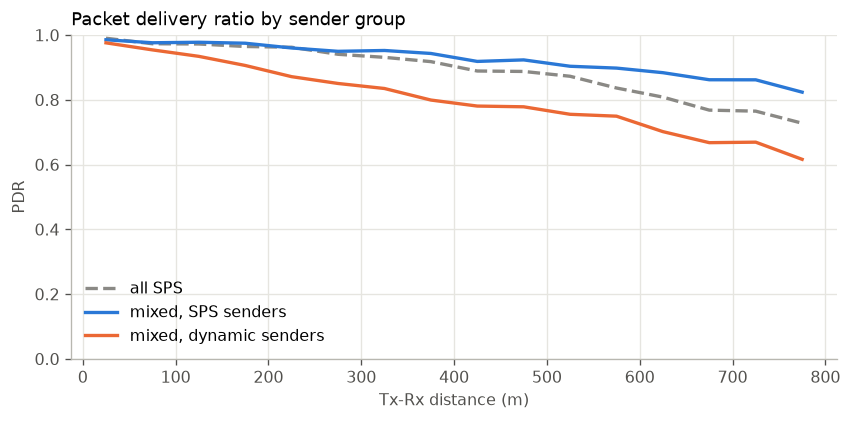

In [4]:
fig, ax = plt.subplots()
series = {"all SPS": (all_sps.rx, range(1, 121), mr.NEUTRAL, "--"),
          "mixed, SPS senders": (half.rx, sps_nodes, mr.SERIES_COLORS[0], "-"),
          "mixed, dynamic senders": (half.rx, dyn_nodes, mr.SERIES_COLORS[1], "-")}
for label, (rx, nodes, color, style) in series.items():
    pdr = mr.pdr_by_distance(rx[rx.txID.isin(nodes)], bin_m=50, max_m=800)
    ax.plot(pdr.index, pdr.values, label=label, color=color, linestyle=style)
ax.set_xlabel("Tx-Rx distance (m)")
ax.set_ylabel("PDR")
ax.set_ylim(0, 1)
ax.legend()
ax.set_title("Packet delivery ratio by sender group")
plt.tight_layout()

**Reading.** Nodes keep their own behaviour, and mixing is safe for the SPS group.

| Senders | Near PDR | Near collisions |
|---|---|---|
| All SPS | 0.97 | 2.3 % |
| Mixed, SPS senders | 0.97 | 2.0 % |
| Mixed, dynamic senders | 0.91 | 7.2 % |
| All dynamic | 0.88 | 10 % |

SPS senders lose nothing to their dynamic neighbours in this run. Dynamic senders gain from them: 0.91 against 0.88, because half the channel is now reservations they can avoid, whereas nobody can avoid them.

This is one seed at one load (CBR 0.21). Repeat with `--runNo` and at higher density before concluding.

## Adding a truly different scheduler

Adaptive reservation (`adaptive`) is an example already in the code: a small class, one attribute, and one hook in `V2XSelectResources`.

`V2XSelectResources` is not virtual and there is no factory, so a new algorithm needs one small change. The simplest route keeps sensing and replaces the choice:

1. Add an attribute, for example an enum `SelectionRule`, in `NrV2XUeMac::GetTypeId`.
2. At the uniform draw in `V2XSelectResources`, branch on it. `finalL2` holds every candidate that survived sensing, with its slot and subchannel.
3. Do the same in `V2XChangeResources` if re-evaluation should use the same rule.
4. Add the option to `ApplySchedulerOption` in `scratch/HIGHWAY.cc`, and a case to `tests/test_integration.py`.

For a rule that replaces sensing itself, split `V2XSelectResources` into a virtual `SelectResources` and subclass `NrV2XUeMac`. It is created in `nist-lte-helper.cc` by `CreateObjectWithAttributes<NrV2XUeMac>`, which would become a factory. This is a larger change. Say if you want it.